In [1]:
amostra= '23_08'

In [2]:
import tensorflow as tf
import keras
print(tf.__version__)
print(keras.__version__)

2024-10-23 18:57:43.587428: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-10-23 18:57:43.594986: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-23 18:57:43.604971: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-23 18:57:43.604988: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-23 18:57:43.612312: I tensorflow/core/platform/cpu_feature_gua

2.16.2
3.3.3


In [3]:
#Make sure the GPU is available. 
import tensorflow as tf
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


2024-10-23 18:57:44.372562: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:44.388395: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:44.388430: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:44.473604: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:44.473647: I external/local_xla/xla/stream_executor

In [4]:
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

2024-10-23 18:57:44.484045: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:44.484102: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:44.484120: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [5]:
import segmentation_models_3D as sm


Segmentation Models: using `keras` framework.


In [6]:
from skimage import io
from patchify import patchify, unpatchify
import numpy as np
from matplotlib import pyplot as plt
from keras import backend as K
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import os
import gc

In [7]:
import albumentations as A

# Data Augmentation
augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Transpose(),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.50, rotate_limit=45, p=.75),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, alpha_affine=None, p=0.5),
    A.GridDistortion(p=0.5),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.5),
     A.OpticalDistortion(),
])

INFO:albumentations.check_version:A new version of Albumentations is available: 1.4.19 (you have 1.4.12). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


In [8]:
def readImages(folder, n_patch = 64, step = 64):
    file_combined = os.path.join(folder,'output_combined_matriz_fibras.tif')
    file_fibras = os.path.join(folder,'output_fibras.tif')

    image = io.imread(file_combined)
    mask = io.imread(file_fibras)
    image_patches = patchify(image, (n_patch, n_patch, n_patch), step=step)
    mask_patches = patchify(mask, (n_patch, n_patch, n_patch), step=step)
    image_patches = np.reshape(image_patches, (-1, image_patches.shape[3], image_patches.shape[4], image_patches.shape[5]))
    mask_patches = np.reshape(mask_patches, (-1, mask_patches.shape[3], mask_patches.shape[4], mask_patches.shape[5]))
    return image_patches, mask_patches

In [9]:
# Função para criar o conjunto de treino (sem dividir percent_train, LOO gerencia isso)
def createTrainLOO(folders, test_folder, augmentData=True):
    train_images = []
    train_masks = []
    
    # Excluímos a pasta de teste e usamos o restante para treinamento
    selected_folders = [folder for folder in folders if folder != test_folder]
    
    for folder in selected_folders:
        image_patches, mask_patches = readImages(folder)
        
        if augmentData:
            augment_test_data(image_patches, mask_patches, train_images, train_masks)
        else:
            train_images.extend(image_patches)
            train_masks.extend(mask_patches)
    
    train_images = np.array(train_images).astype(np.uint8)
    train_masks = np.array(train_masks).astype(np.uint8)
    
    return train_images, train_masks

In [10]:
def apply_augmentation(image, mask):
    augmented = augmentation(image=image, mask=mask)
    return augmented['image'], augmented['mask']

def augment_test_data(image_patches, mask_patches, train_images, train_masks):
    for i in range(image_patches.shape[0]):
        img_patch = image_patches[i, :, :, :]
        mask_patch = mask_patches[i, :, :, :]
        train_images.append(img_patch)
        train_masks.append(mask_patch)
        img_aug, mask_aug = apply_augmentation(img_patch, mask_patch)
        train_images.append(img_aug)
        train_masks.append(mask_aug)

def preprocess_data(images, masks, n_classes=2):
    images = (images / 255).astype(np.uint8)
    masks = (masks / 255).astype(np.uint8)
    images = np.stack((images,) * 3, axis=-1)  # Empilhando os canais de imagem para RGB
    masks = np.expand_dims(masks, axis=-1)  # Expandindo dimensões das máscaras
    masks_cat = to_categorical(masks, num_classes=n_classes)
    return images, masks_cat

In [11]:
import os
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=false'

In [12]:
#Define parameters for our model.

policy = tf.keras.mixed_precision.Policy('mixed_float16')
tf.keras.mixed_precision.set_global_policy(policy)

In [13]:
from keras.models import Model
from keras.layers import Conv3D, Conv3DTranspose, MaxPooling3D, Add, BatchNormalization, GroupNormalization, Input, Activation, Lambda, UpSampling3D, Concatenate
from keras import initializers


def res_unet(filter_root, layers, n_class=2, input_size=(10, 256, 256, 1), activation='relu', norm='BN', group_filter=32, final_activation='softmax'):
    """
    Build UNet model with ResBlock.

    Args:
        filter_root (int): Number of filters to start with in first convolution.
        n_class (int, optional): How many classes in the output layer. Defaults to 2.
        input_size (tuple, optional): Input image size. Defaults to (256, 256, 1).
        activation (str, optional): activation to use in each convolution. Defaults to 'relu'.
        batch_norm (bool, optional): To use Batch normaliztion or not. Defaults to True.
        final_activation (str, optional): activation for output layer. Defaults to 'softmax'.

    Returns:
        obj: keras model object
    """

    if group_filter < filter_root:
        group_filter = filter_root
    
    inputs = Input(input_size)
    x = inputs
    # Dictionary for long connections
    long_connection_store = {}
    # Dictionary for deep supervision
    outputs = []
    # Down sampling
    for i in range(layers):
        out_channel = 2**i * filter_root
        print("out_channel downsampling: {}".format(out_channel))

        # Residual/Skip connection
        res = Conv3D(out_channel, kernel_size=1,
                     padding='same', use_bias=False, name="Identity{}_1".format(i))(x)

        # First Conv Block with Conv, BN and activation
        conv1 = Conv3D(out_channel, kernel_size=3, padding='same', name="Conv{}_1".format(i))(x)
        if norm=='BN':
            conv1 = BatchNormalization(name="BN{}_1".format(i))(conv1)
        elif norm=='GN':
            conv1 = GroupNormalization(groups=group_filter, name="GN{}_1".format(i))(conv1)
        act1 = Activation(activation, name="Act{}_1".format(i))(conv1)

        # Second Conv block with Conv and BN only
        conv2 = Conv3D(out_channel, kernel_size=3, padding='same', name="Conv{}_2".format(i))(act1)
        if norm=='BN':
            conv2 = BatchNormalization(name="BN{}_2".format(i))(conv2)
        elif norm=='GN':
            conv2 = GroupNormalization(groups=group_filter, name="GN{}_2".format(i))(conv2)
        resconnection = Add(name="Add{}_1".format(i))([res, conv2])

        act2 = Activation(activation, name="Act{}_2".format(i))(resconnection)

        # Max pooling
        if i < layers - 1:
            long_connection_store[str(i)] = act2
            x = MaxPooling3D(padding='same', name="MaxPooling{}_1".format(i))(act2)
        else:
            x = act2
    print("\n")
    # Upsampling
    for i in range(layers - 2, -1, -1):
        print("i upsampling: {}".format(i))

        out_channel = 2**(i) * filter_root
        print("out_channel upsampling: {}".format(out_channel))

        # long connection from down sampling path.
        long_connection = long_connection_store[str(i)]
        print("long_connection: {}".format(long_connection))

        up1 = UpSampling3D(name="UpSampling{}_1".format(i))(x)
        up_conv1 = Conv3D(out_channel, 2, activation='relu', padding='same', name="upsamplingConv{}_1".format(i))(up1)
        print("up_conv1: {}".format(up_conv1))
        #  Concatenate.
        up_conc = Concatenate(axis=-1, name="upConcatenate{}_1".format(i))([up_conv1, long_connection])

        #  Convolutions
        up_conv2 = Conv3D(out_channel, 3, padding='same', name="upConv{}_1".format(i))(up_conc)
        if norm=='BN':
            up_conv2 = BatchNormalization(name="upBN{}_1".format(i))(up_conv2)
        elif norm=='GN':
            up_conv2 = GroupNormalization(groups=group_filter, name="upGN{}_1".format(i))(up_conv2)
        up_act1 = Activation(activation, name="upAct{}_1".format(i))(up_conv2)

        up_conv2 = Conv3D(out_channel, 3, padding='same', name="upConv{}_2".format(i))(up_act1)
        if norm=='BN':
            up_conv2 = BatchNormalization(name="upBN{}_2".format(i))(up_conv2)
        elif norm=='GN':
            up_conv2 = GroupNormalization(groups=group_filter, name="upGN{}_2".format(i))(up_conv2)

        # Residual/Skip connection
        res = Conv3D(out_channel, kernel_size=1,
                     padding='same', use_bias=False, name="upIdentity{}_1".format(i))(up_conc)

        resconnection = Add(name="upAdd{}_1".format(i))([res, up_conv2])

        x = Activation(activation, name="upAct{}_2".format(i))(resconnection)

    # Final convolution
    output = Conv3D(n_class, 1, padding='same',
                    activation=final_activation, name='output')(x)
    outputs.append(output)
    return Model(inputs, outputs=outputs, name='U-ResNet')

In [14]:
from tensorflow.keras.optimizers.schedules import ExponentialDecay


# Define configuration parameters
initial_learning_rate = 0.0001
min_lr = 0.000001
max_lr = 0.001
rampup_epochs = 10
sustain_epochs = 0
exp_decay = 0.8

# Define the scheduling function
def schedule(epoch):
  def lr(epoch, initial_learning_rate, min_lr, max_lr, rampup_epochs, sustain_epochs, exp_decay):
    if epoch < rampup_epochs:
      lr = (max_lr - initial_learning_rate)/rampup_epochs * epoch + initial_learning_rate
    elif epoch < rampup_epochs + sustain_epochs:
      lr = max_lr
    else:
      lr = (max_lr - min_lr) * exp_decay**(epoch-rampup_epochs-sustain_epochs) + min_lr
    return lr
  return lr(epoch, initial_learning_rate, min_lr, max_lr, rampup_epochs, sustain_epochs, exp_decay)

lr_callback = tf.keras.callbacks.LearningRateScheduler(lambda epoch: schedule(epoch), verbose=True)

In [15]:
# Função de criação e compilação do modelo
def build_model(input_shape, n_classes=2, filter_root=64, layers=5, group_filter=64, initial_lr=0.0001):
    dice_loss = sm.losses.DiceLoss(class_weights=np.array([0.5, 0.5], dtype=np.float32))
    focal_loss = sm.losses.CategoricalFocalLoss()
    total_loss = dice_loss + focal_loss

    metrics = [sm.metrics.IOUScore(threshold=0.5), sm.metrics.FScore(threshold=0.5)]

    # Definir modelo
    model = res_unet(
        filter_root=filter_root,
        layers=layers,
        n_class=n_classes,
        input_size=input_shape,
        activation='relu',
        norm='GN',
        group_filter=group_filter,
        final_activation='softmax'
    )

    optimizer = keras.optimizers.Adam(learning_rate=initial_lr)
    model.compile(optimizer=optimizer, loss=total_loss, metrics=metrics)
    print(model.summary())
    return model

In [16]:
# Função para converter para float32
def convert_to_float32(image, mask):
    image = tf.cast(image, tf.float32)
    mask = tf.cast(mask, tf.float32)
    return image, mask

In [17]:
from numba import cuda
import ctypes


def free_gpu(variable_names, globals_dict):
    """
    Deleta variáveis, libera a memória da CPU e limpa a memória da GPU.

    Parâmetros:
    - variable_names: Lista de strings com os nomes das variáveis a serem deletadas.
    - globals_dict: O dicionário global onde as variáveis estão armazenadas (geralmente `globals()`).
    """
    # Deleta as variáveis da CPU
    for var in variable_names:
        if var in globals_dict:
            del globals_dict[var]  # Deleta a variável
    gc.collect()  # Coletor de lixo para liberar memória da CPU

    # Libera a memória da GPU em TensorFlow
    try:
        tf.keras.backend.clear_session()  # Libera recursos da GPU no TensorFlow
    except:
        pass

    # Libera a memória da GPU com Numba (CUDA)
    try:
        device = cuda.get_current_device()
        device.reset()  # Reseta o dispositivo GPU
    except:
        pass
        
    libc = ctypes.CDLL("libc.so.6") # clearing cache 
    libc.malloc_trim(0)


In [18]:
import contextlib

@contextlib.contextmanager
def clear_memory():
    try:
        yield
    finally:
        gc.collect()

In [19]:
# Função principal para treinamento com LOO
def train_with_LOO(X_train, X_test, y_train, y_test,model, test_folder, batch_size=1, n_epochs=50, filter_root=64, layers=5, group_filter=64): 

    # Definir o caminho para salvar o modelo
    folder_trained_models = 'trained_models/'
    name_model = f'unet-resblock_model_test_{test_folder}_{filter_root}_filter_{layers}_layers'
    namefile = folder_trained_models + name_model + '.keras'
    checkpoint_callback = ModelCheckpoint(namefile, 
                                          monitor='val_iou_score', 
                                          save_best_only=True, 
                                          mode='max', 
                                          verbose=1)

    early_stopping = EarlyStopping(monitor='val_iou_score', patience=10, mode='max', restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_iou_score', factor=0.2, patience=10, min_lr=min_lr)
    callbacks = [checkpoint_callback, reduce_lr, lr_callback, early_stopping]
    # Limpeza da memória
    tf.keras.backend.clear_session()

    # Treinamento do modelo
    history = model.fit(X_train,
                        y_train,
                        batch_size=batch_size,
                        epochs=n_epochs,
                        validation_data=(X_test, y_test),
                        callbacks= callbacks,
                        verbose=1)

    # Avaliação do modelo
    scores = model.evaluate(test_images, test_masks_cat, verbose=0, batch_size=2)
    print(f"Test_folder {test_folder} - Test Loss: {scores[0]}, Test IoU: {scores[1]}, Dice: {scores[2]}\n")
    return model


In [20]:
path_steel_stl= '../../steel/stl/'
paths = [os.path.join(path_steel_stl, folder) for folder in os.listdir(path_steel_stl)]
folders = [folder for folder in paths if os.path.isdir(folder)]
test_folder = amostra

In [21]:
n_classes=2
augmentData = False
batch_size = 1
n_epochs = 100
filter_root=64
layers=5
group_filter=16

In [22]:
path_test_folder = path_steel_stl + test_folder
# Dividindo os dados (test_folder para teste e o restante para treino)
train_images, train_masks = createTrainLOO(folders, path_test_folder, augmentData)
test_images, test_masks = readImages(path_test_folder)

# Pré-processamento dos dados
train_images, train_masks_cat = preprocess_data(train_images, train_masks, n_classes)
test_images, test_masks_cat = preprocess_data(test_images, test_masks, n_classes)
print(f'train_images shape: {train_images.shape}')

X_train, X_test, y_train, y_test = train_test_split(train_images, train_masks_cat, test_size = 0.10, random_state = 0)


# Construção e compilação do modelo
input_shape = (train_images.shape[1], train_images.shape[2], train_images.shape[3], train_images.shape[4])
model = build_model(input_shape=input_shape, n_classes=n_classes, filter_root=filter_root, layers=layers, group_filter=group_filter)

train_images shape: (640, 64, 64, 64, 3)
out_channel downsampling: 64
out_channel downsampling: 128
out_channel downsampling: 256
out_channel downsampling: 512
out_channel downsampling: 1024


i upsampling: 3
out_channel upsampling: 512
long_connection: <KerasTensor shape=(None, 8, 8, 8, 512), dtype=float16, sparse=False, name=keras_tensor_35>
up_conv1: <KerasTensor shape=(None, 8, 8, 8, 512), dtype=float16, sparse=False, name=keras_tensor_46>
i upsampling: 2
out_channel upsampling: 256
long_connection: <KerasTensor shape=(None, 16, 16, 16, 256), dtype=float16, sparse=False, name=keras_tensor_26>
up_conv1: <KerasTensor shape=(None, 16, 16, 16, 256), dtype=float16, sparse=False, name=keras_tensor_57>
i upsampling: 1
out_channel upsampling: 128
long_connection: <KerasTensor shape=(None, 32, 32, 32, 128), dtype=float16, sparse=False, name=keras_tensor_17>
up_conv1: <KerasTensor shape=(None, 32, 32, 32, 128), dtype=float16, sparse=False, name=keras_tensor_68>


2024-10-23 18:57:49.288784: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:49.288854: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:49.288879: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:49.289044: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 18:57:49.289057: I tensorflow/core/common_runtime/gpu/gpu

i upsampling: 0
out_channel upsampling: 64
long_connection: <KerasTensor shape=(None, 64, 64, 64, 64), dtype=float16, sparse=False, name=keras_tensor_8>
up_conv1: <KerasTensor shape=(None, 64, 64, 64, 64), dtype=float16, sparse=False, name=keras_tensor_79>


Model: "U-ResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 64, 3)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv0_1 (Conv3D)    │ (None, 64, 64,    │      5,248 │ input_layer[0][0] │
│                     │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GN0_1               │ (None, 64, 64,    │        128 │ Conv0_1[0][0]     │
│ (GroupNormalizatio… │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Act0_1 (Activation) │ (None, 64, 64,    │          0 │ GN0_1[0][0]       │
│                     │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv0_2 (Conv3D)    │ (None, 64, 64,    │    110,656 │ Act0_1[0][0]      │
│                     │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Identity0_1         │ (None, 64, 64,    │        192 │ input_layer[0][0] │
│ (Conv3D)            │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GN0_2               │ (None, 64, 64,    │        128 │ Conv0_2[0][0]     │
│ (GroupNormalizatio… │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Add0_1 (Add)        │ (None, 64, 64,    │          0 │ Identity0_1[0][0… │
│                     │ 64, 64)           │            │ GN0_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Act0_2 (Activation) │ (None, 64, 64,    │          0 │ Add0_1[0][0]      │
│                     │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ MaxPooling0_1       │ (None, 32, 32,    │          0 │ Act0_2[0][0]      │
│ (MaxPooling3D)      │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_1 (Conv3D)    │ (None, 32, 32,    │    221,312 │ MaxPooling0_1[0]… │
│                     │ 32, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GN1_1               │ (None, 32, 32,    │        256 │ Conv1_1[0][0]     │
│ (GroupNormalizatio… │ 32, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Act1_1 (Activation) │ (None, 32, 32,    │          0 │ GN1_1[0][0]       │
│                     │ 32, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_2 (Conv3D)    │ (None, 32, 32,    │    442,496 │ Act1_1[0][0]      │
│                     │ 32, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Identity1_1         │ (None, 32, 32,    │      8,192 │ MaxPooling0_1[0]… │
│ (Conv3D)            │ 32, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ GN1_2               │ (None, 32, 32,    │        256 │ Conv1_2[0][0]     │
│ (GroupNormalizatio… │ 32, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Add1_1 (Add)        │ (None, 32, 32,    │          0 │ Identity1_1[0][0

 Total params: 91,700,802 (349.81 MB)

 Trainable params: 91,700,802 (349.81 MB)

 Non-trainable params: 0 (0.00 B)

None


In [23]:
#Fit the model
import time
start_time = time.time()

model = train_with_LOO(X_train, X_test, y_train, y_test,model, test_folder, batch_size, n_epochs, filter_root=filter_root, layers=layers, group_filter=group_filter)


Epoch 1: LearningRateScheduler setting learning rate to 0.0001.
Epoch 1/100


I0000 00:00:1729720680.762055  238385 service.cc:145] XLA service 0x7f8bf8003210 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1729720680.762091  238385 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9
2024-10-23 18:58:00.906091: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-10-23 18:58:01.706139: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907
2024-10-23 18:58:08.131912: W external/local_tsl/tsl/framework/bfc_allocator.cc:296] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.55GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
I0000 00:00:1729720697.606494  238385 asm_compiler.cc:369] ptxas warning : Registers

576/576 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - f1-score: 0.7888 - iou_score: 0.7028 - loss: 0.6238
Epoch 1: val_iou_score improved from -inf to 0.74790, saving model to trained_models/unet-resblock_model_test_23_08_64_filter_5_layers.keras
576/576 ━━━━━━━━━━━━━━━━━━━━ 95s 127ms/step - f1-score: 0.7888 - iou_score: 0.7029 - loss: 0.6238 - val_f1-score: 0.8281 - val_iou_score: 0.7479 - val_loss: 0.5999 - learning_rate: 1.0000e-04

Epoch 2: LearningRateScheduler setting learning rate to 0.00019.
Epoch 2/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - f1-score: 0.8443 - iou_score: 0.7634 - loss: 0.5917
Epoch 2: val_iou_score did not improve from 0.74790
576/576 ━━━━━━━━━━━━━━━━━━━━ 67s 115ms/step - f1-score: 0.8443 - iou_score: 0.7634 - loss: 0.5917 - val_f1-score: 0.8223 - val_iou_score: 0.7405 - val_loss: 0.6030 - learning_rate: 1.9000e-04

Epoch 3: LearningRateScheduler setting learning rate to 0.00028.
Epoch 3/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - f1-score: 0.8565 - iou_score

In [24]:
end_time = time.time()
def format_time(seconds):
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:.0f} horas, {minutes:.0f} minutos e {seconds:.2f} segundos"

elapsed_time = end_time - start_time
formatted_time = format_time(elapsed_time)
print(f"Tempo total: {formatted_time}")

Tempo total: 0 horas, 41 minutos e 57.53 segundos


In [25]:
gc.collect()

6363

In [26]:
path_steel_stl= '../../steel/stl/'
folder = os.path.join(path_steel_stl, amostra)
file_combined = os.path.join(folder,'output_combined_matriz_fibras.tif')
file_fibras = os.path.join(folder,'output_fibras.tif')
input_shape = (64,64,64)
image = io.imread(file_combined)
img_patches = patchify(image, input_shape, step=64)

In [27]:
pred = model.predict(test_images, batch_size=2)
pred.shape

2024-10-23 19:39:52.176338: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step


(64, 64, 64, 64, 2)

In [28]:
test_masks_cat.shape

(64, 64, 64, 64, 2)

In [29]:
print("Dtype of test_masks_cat:", test_masks_cat.dtype)
print("Dtype of predictions:", pred.dtype)

Dtype of test_masks_cat: float64
Dtype of predictions: float16


In [30]:
print("Shape of test_masks_cat:", test_masks_cat.shape)
print("Shape of predictions:", pred.shape)

Shape of test_masks_cat: (64, 64, 64, 64, 2)
Shape of predictions: (64, 64, 64, 64, 2)


In [31]:
# Instanciando as métricas
iou_metric = sm.metrics.IOUScore(threshold=0.5)
fscore_metric = sm.metrics.FScore(threshold=0.5)

test_masks_cat = tf.cast(test_masks_cat, tf.float32)
pred = tf.cast(pred, tf.float32)

# Calculando as métricas
iou_value = iou_metric(test_masks_cat, pred).numpy()
fscore_value = fscore_metric(test_masks_cat, pred).numpy()

print("IOU Score:", iou_value)
print("Dice :", fscore_value)

IOU Score: 0.8819275
Dice : 0.9340694


In [32]:
pred_argmax = np.argmax(pred, axis=4)[:,:,:]

In [33]:
pred_argmax.shape

(64, 64, 64, 64)

In [34]:
pred_reshaped = np.reshape(pred_argmax, 
                                        (img_patches.shape[0], img_patches.shape[1], img_patches.shape[2],
                                         img_patches.shape[3], img_patches.shape[4], img_patches.shape[5]) )
print(pred_reshaped.shape)

(4, 4, 4, 64, 64, 64)


In [35]:
reconstructed_image = unpatchify(pred_reshaped, image.shape)
print(reconstructed_image.shape)

(256, 256, 256)


In [36]:
np.unique(reconstructed_image)

array([0, 1])

In [37]:
test_mask_reshaped = np.reshape(test_masks, 
                                        (img_patches.shape[0], img_patches.shape[1], img_patches.shape[2],
                                         img_patches.shape[3], img_patches.shape[4], img_patches.shape[5]) )
print(test_mask_reshaped.shape)

(4, 4, 4, 64, 64, 64)


In [38]:
reconstructed_mask = unpatchify(test_mask_reshaped, image.shape)

In [39]:
reconstructed_mask.shape

(256, 256, 256)

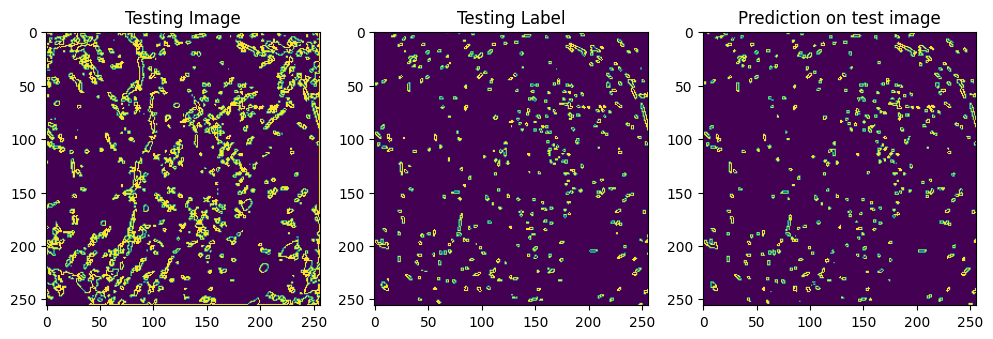

In [40]:
slice = 100
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(image[slice,:,:])
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(reconstructed_mask[slice,:,:])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(reconstructed_image[slice,:,:])
plt.show()

In [41]:
from tifffile import imsave

def generate3D(amostra, reconstructed_image):
    
    name_file = '3D_result/'+ amostra + '_segmented.tif'
    imsave(name_file, reconstructed_image)

In [42]:
generate3D(amostra, reconstructed_image)

/tmp/ipykernel_238280/473623651.py:6: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave(name_file, reconstructed_image)
